In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os

# Add parent directory to path to find nl2sparql
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from ABSTAT.abstat_2 import ABSTAT_v2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Loading classes document store from cache: /Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/nl2sparql/tools/tools-cache/classes_309e95b8_document_store.json
✓ Loaded 13 classes from cache
Loading properties document store from cache: /Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/nl2sparql/tools/tools-cache/properties_2f1d845b_document_store.json


DependencyConflict: requested: "smolagents >= 1.2.2.dev0" but found: "None"


✓ Loaded 110 properties from cache
🔭 OpenTelemetry Tracing Details 🔭
|  Phoenix Project: kg_expert
|  Span Processor: SimpleSpanProcessor
|  Collector Endpoint: localhost:4317
|  Transport: gRPC
|  Transport Headers: {}
|  
|  Using a default SpanProcessor. `add_span_processor` will overwrite this default.
|  
|  ⚠️ WARNING: It is strongly advised to use a BatchSpanProcessor in production environments.
|  
|  `register` has set this TracerProvider as the global OpenTelemetry default.
|  To disable this behavior, call `register` with `set_global_tracer_provider=False`.



In [2]:
# Initialize the extractor
abstat = ABSTAT_v2(endpoint='sockg-local')

In [3]:
# 2. Run the Main Process
# This fetches top K frequent properties and extracts patterns for them
# max_triples limits the number of instances sampled per property to avoid timeouts on huge queries
abstat.process_properties(property_limit=300, max_triples=50000)

Fetching top properties by frequency (limit=300)...
Found 215 properties.

Processing 215 properties...


Analyzing properties:   0%|          | 0/215 [00:00<?, ?it/s]

Property hasUnit: Found 1 raw patterns.
Property numericValue: Found 1 raw patterns.
Property quantityValue: Found 1 raw patterns.
Property hasMeasurement: Found 4 raw patterns.
Property of: Found 1 raw patterns.
Property date: Found 7 raw patterns.
Property usesTreatment: Found 7 raw patterns.
Property fromUnit: Found 7 raw patterns.
Property standardUncertainty: Found 1 raw patterns.
Property isInterpolated: Found 1 raw patterns.
Property hasCrop: Found 11 raw patterns.
Property badValueFlag: Found 1 raw patterns.
Property weatherAt: Found 1 raw patterns.
Property hasChamberPlacement: Found 1 raw patterns.
Property startDate: Found 8 raw patterns.
Property upperDepth: Found 3 raw patterns.
Property lowerDepth: Found 3 raw patterns.
Property hasGrowthStage: Found 12 raw patterns.
Property treatmentHasAmendment: Found 1 raw patterns.
Property unitHasAmendment: Found 1 raw patterns.
Property hasTillageEvent: Found 1 raw patterns.
Property treatmentHasTillageManagement: Found 1 raw patte

Sampling 10 patterns from 343 available...
Plotting schema graph with 10 patterns...


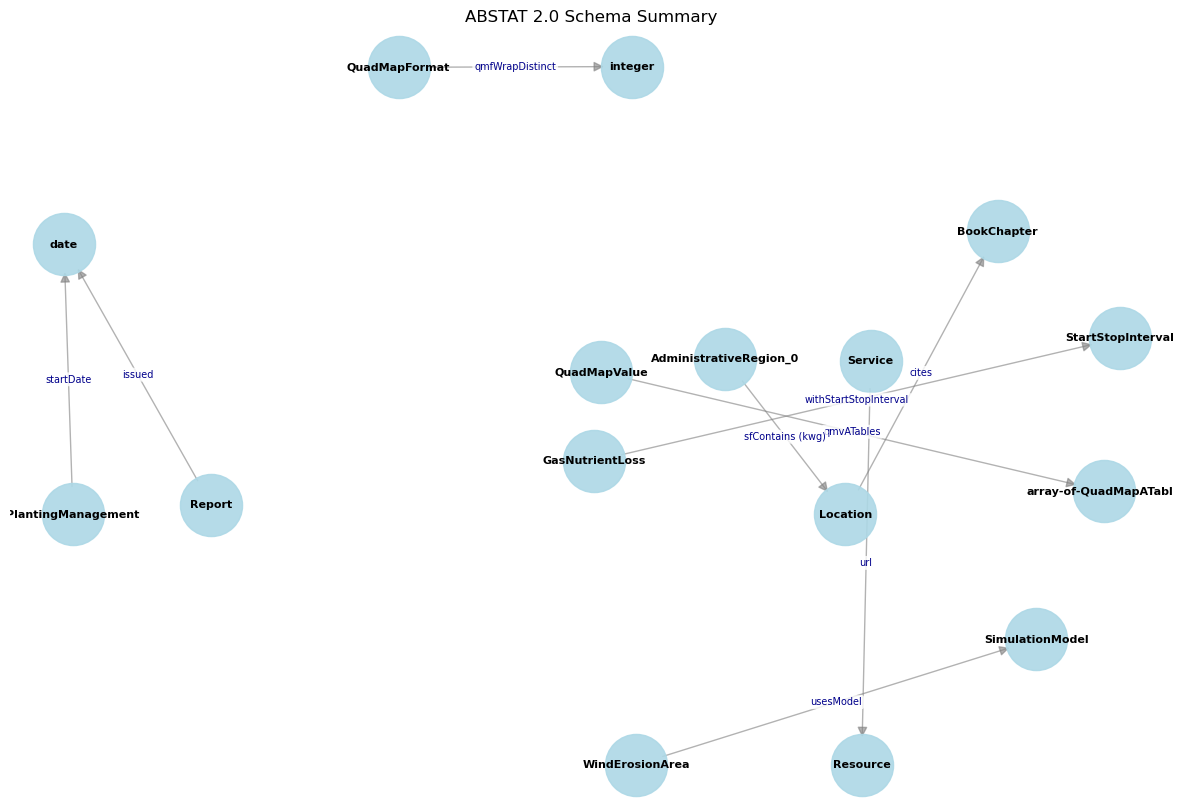

In [4]:
# 3. Visualize the Schema
abstat.plot_schema_graph(exclude_properties=['label', 'prefLabel', 'comment', 'description', 'name', 'type'], max_edges=10)

In [5]:
# 4. View the Data
abstat.print_data()

,Subject Type,Property,Object Type,Count
340,array-of-QuadMapFormat,_2,QuadMapFormat,13
342,array-of-QuadMapFormat,_3,QuadMapFormat,10
367,array-of-QuadMapFormat,_4,QuadMapFormat,3
366,array-of-QuadMapFormat,_5,QuadMapFormat,3
283,Person,additionalName,Text,100
...,...,...,...,...
182,BookChapter,label,string,2
189,AdministrativeRegion_0,label,string,2
164,AnnotationProperty (AnnotationProperty),label,string,1
169,Report,label,string,1


In [6]:
# Demo: Standalone function to get domain-range combinations for a single property
from ABSTAT.abstat_2 import get_property_domain_range
import pandas as pd

# Example: Get domain-range combinations for a specific property
property_uri = "http://www.w3.org/2000/01/rdf-schema#label"  # Change this to any property you want to analyze
results = get_property_domain_range(property_uri, endpoint='sockg-local', max_triples=5000)

# Display as DataFrame
if results:
    df = pd.DataFrame(results)
    # Add short names for readability
    df['subject_type_short'] = df['subject_type'].apply(lambda x: x.split('/')[-1].split('#')[-1])
    df['object_type_short'] = df['object_type'].apply(lambda x: x.split('/')[-1].split('#')[-1])
    display(df[['subject_type_short', 'object_type_short', 'count']].sort_values('count', ascending=False))
else:
    print("No domain-range pairs found for this property.")

,subject_type_short,object_type_short,count
42,Cultivar,string,308
27,Parameter,string,156
17,JournalArticle,string,149
40,ActiveIngredient,string,84
38,AmendmentType,string,73
1,TillageMethod,string,64
26,Location,string,58
35,7140,string,49
39,PesticideTarget,string,43
14,AdministrativeRegion_1,string,36


In [8]:
# 5. Connect Subgraph Mining Demo
from ABSTAT.subgraph_miner import SubgraphMiner
import networkx as nx
import matplotlib.pyplot as plt

# Initialize Miner
# We use existing 'abstat' instance which already has computed patterns
miner = SubgraphMiner(abstat, min_support=10) # Lower support for demo

print("Mining subgraphs with at least 4 types (Diversity Mode)...")
# Now also samples m=5 entities per type and saves each subgraph to YAML
subgraphs = miner.mine(k=5, max_results=20, max_time=60, diversity=True, m=5, output_dir="./subgraphs_output")

print(f"Found {len(subgraphs)} subgraphs:")

def visualize_subgraph(sg, index):
    print(f"\n{'='*30} Subgraph {index+1} {'='*30}")
    print(f"Support: {sg.get('support', 'N/A')}")
    
    # 1. Text Summary
    types_short = [t.split('/')[-1].split('#')[-1] for t in sg['types']]
    print(f"Types ({len(types_short)}):")
    print(", ".join(types_short))
    print("\nEdges:")
    
    G = nx.DiGraph() 
    edge_labels = {}
    
    for s, p, o in sg['edges']:
        s_base = s.split('/')[-1].split('#')[-1]
        o_base = o.split('/')[-1].split('#')[-1]
        p_base = p.split('/')[-1].split('#')[-1]
        
        G.add_edge(s_base, o_base)
        # For graph viz, we might overwrite if multiple edges exist between same nodes
        edge_labels[(s_base, o_base)] = p_base 
        
        print(f"  {s_base:20} -- {p_base:^20} --> {o_base}")
        print(f"    (Full: {s} -- {p} --> {o})\n")

    # 2. Graph Plot
    if len(sg['types']) > 1:
        plt.figure(figsize=(10, 6))
        # Use spring layout
        pos = nx.spring_layout(G, k=0.8, seed=42)
        
        # Draw nodes
        nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='lightblue', alpha=0.9)
        nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')
        
        # Draw edges with improved arrows
        # passing node_size ensures arrows stop at the node border
        nx.draw_networkx_edges(G, pos, 
                               arrowstyle='-|>', 
                               arrowsize=25, 
                               edge_color='gray', 
                               node_size=2000, 
                               width=1.5)
        
        # Draw labels
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='darkblue', font_size=8)
        
        plt.title(f"Subgraph {index+1} Visualization")
        plt.axis('off')
        plt.show()

for i, sg in enumerate(subgraphs):
    visualize_subgraph(sg, i)

Mining subgraphs with at least 4 types (Diversity Mode)...


Explored Candidates: 0it [00:00, ?it/s]

Saved subgraph 1 to ./subgraphs_output/subgraph_001.yaml
Saved subgraph 2 to ./subgraphs_output/subgraph_002.yaml


KeyboardInterrupt: 